# ISOT Fake News Detection: ModernBERT + Bi-GRU

- **Data:** ISOT (`True.csv` = real, `Fake.csv` = fake). Upload both files to the Colab file panel (or mount Drive and change `DATA_DIR`).
- **Encoder:** `answerdotai/ModernBERT-base`, first layers frozen, **last N layers fine-tuned** (this is the main accuracy boost over a fully frozen encoder).
- **Head:** Bi-GRU with masked mean + max pooling, then a linear classifier.
- **Runtime:** Colab GPU (T4 is fine): *Runtime > Change runtime type > T4 GPU*.
- **Leakage note:** ISOT real articles carry giveaways such as `WASHINGTON (Reuters) -`, and the `subject` column almost perfectly separates the classes. Those are removed here, so the score reflects real language understanding rather than shortcuts. Duplicates are dropped *before* splitting so test articles never appear in train.

In [ ]:
# STEP 1: Imports, seed, device
import os, re, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import unicodedata



import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

print("PyTorch:", torch.__version__)
print("Device:", device, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU")

In [ ]:
# STEP 2: Config
DATA_DIR    = "."                                 # folder containing True.csv and Fake.csv
MODEL_NAME  = "answerdotai/ModernBERT-base"
MAX_LEN     = 256                                 # news articles are long, 256 tokens >> 128
BATCH_SIZE  = 32
SEED        = 42

REMOVE_LEAKAGE  = True    # strip "(Reuters)" datelines, URLs, twitter links, etc.
UNFREEZE_LAST_N = 2       # fine-tune the last N ModernBERT layers (0 = fully frozen encoder)

# Bi-GRU head
HIDDEN_SIZE = 128
NUM_LAYERS  = 1
DROPOUT     = 0.3

EPOCHS      = 4
PATIENCE    = 2
LR_HEAD     = 1e-3
LR_ENCODER  = 2e-5

In [ ]:

# STEP 3: Load, clean and deduplicate ISOT

true_df = pd.read_csv("/content/True.csv")
fake_df = pd.read_csv("/content/Fake.csv")

true_df["label"] = 0
fake_df["label"] = 1
df = pd.concat([true_df, fake_df], ignore_index=True)

URL_RE = re.compile(r"https?://\S+|www\.\S+|pic\.twitter\.com/\S+", re.I)
REUTERS_RE = re.compile(r"\(\s*Reuters\s*\)|\bReuters\b", re.I)
CREDIT_RE = re.compile(
    r"^\s*(?:featured\s+)?image\s+via\s+[^\n]{0,120}\.?\s*$|"
    r"^\s*photo\s+by\s+[^\n]{0,120}\.?\s*$|"
    r"^\s*getty\s+images\s*\.?\s*$",
    re.I
)

def clean_text(text: str) -> str:
    t = unicodedata.normalize("NFKC", str(text))

    # Normalize whitespace first so line-anchored credit removal is safe.
    t = "\n".join(line.strip() for line in t.splitlines())

    # Remove URLs.
    t = URL_RE.sub(" ", t)

    # Remove Reuters markers without leaving "( )" behind.
    t = REUTERS_RE.sub(" ", t)

    # Remove only standalone credit/footer lines, not arbitrary text after them.
    t = "\n".join(
        line for line in t.splitlines()
        if not CREDIT_RE.fullmatch(line.strip())
    )

    # Preserve apostrophes and common punctuation; do not destroy contractions.
    t = re.sub(r"[\u2018\u2019]", "'", t)
    t = re.sub(r"[\u201c\u201d]", '"', t)
    t = re.sub(r"\s+", " ", t).strip()

    return t

df["title"] = df["title"].fillna("").apply(clean_text)
df["text"] = df["text"].fillna("").apply(clean_text)
df["content"] = df["title"] + ". " + df["text"]

df = df[df["content"].str.split().str.len() >= 8]
df = df.drop_duplicates("content").reset_index(drop=True)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
df = df[["content", "label"]]

print("Final shape:", df.shape)
print(df["label"].value_counts().rename({0: "Real", 1: "Fake"}))


Final shape: (39085, 2)
label
Real    21194
Fake    17891
Name: count, dtype: int64


In [ ]:
# STEP 4: Stratified 80/10/10 split (after dedup, so no article is in two splits)
train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

31268 3908 3909


In [ ]:
# STEP 5: Tokenizer, Dataset, DataLoaders (dynamic padding)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class NewsDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts, self.labels = texts.tolist(), labels.tolist()
    def __len__(self): return len(self.texts)
    def __getitem__(self, i): return self.texts[i], self.labels[i]

def collate_fn(batch):
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), max_length=MAX_LEN, padding=True,
                    truncation=True, return_tensors="pt")
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"],
            "label": torch.tensor(labels, dtype=torch.long)}

train_loader = DataLoader(NewsDataset(train_df["content"], train_df["label"]),
                          batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader   = DataLoader(NewsDataset(val_df["content"], val_df["label"]),
                          batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collate_fn)
test_loader  = DataLoader(NewsDataset(test_df["content"], test_df["label"]),
                          batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collate_fn)

batch = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in batch.items()})

{'input_ids': (32, 256), 'attention_mask': (32, 256), 'label': (32,)}


In [ ]:
# STEP 6: Model = (partly fine-tuned) ModernBERT + Bi-GRU with mean+max pooling
class ModernBertBiGRU(nn.Module):
    def __init__(self, model_name=MODEL_NAME, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS,
                 dropout=DROPOUT, num_classes=2, unfreeze_last_n=UNFREEZE_LAST_N):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        for p in self.encoder.parameters():
            p.requires_grad = False
        if unfreeze_last_n > 0:
            for layer in self.encoder.layers[-unfreeze_last_n:]:
                for p in layer.parameters():
                    p.requires_grad = True
            for p in self.encoder.final_norm.parameters():
                p.requires_grad = True

        self.gru = nn.GRU(self.encoder.config.hidden_size, hidden_size, num_layers=num_layers,
                          batch_first=True, bidirectional=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * 2 * 2, num_classes)   # (fwd+bwd) x (mean+max)

    def forward(self, input_ids, attention_mask):
        seq = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state.float()
        L = seq.size(1)
        lengths = attention_mask.sum(dim=1).cpu()
        with torch.autocast(device_type="cuda", enabled=False):
            packed = nn.utils.rnn.pack_padded_sequence(seq, lengths, batch_first=True, enforce_sorted=False)
            out, _ = self.gru(packed)
            out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=L)
            m = attention_mask.unsqueeze(-1).float()
            mean_pool = (out * m).sum(1) / m.sum(1).clamp(min=1)
            max_pool  = out.masked_fill(m == 0, -1e4).max(1).values
            feat = torch.cat([mean_pool, max_pool], dim=1)
            return self.fc(self.dropout(feat))

model = ModernBertBiGRU().to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen    = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print(f"Trainable params: {trainable:,} | Frozen params: {frozen:,}")

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 10,721,538 | Frozen params: 138,983,424


In [ ]:
# STEP 7: Optimizer (different LRs), scheduler, weighted loss, AMP scaler
enc_params  = [p for p in model.encoder.parameters() if p.requires_grad]
head_params = list(model.gru.parameters()) + list(model.fc.parameters())
groups = [{"params": head_params, "lr": LR_HEAD}]
if enc_params:
    groups.append({"params": enc_params, "lr": LR_ENCODER})
optimizer = torch.optim.AdamW(groups, weight_decay=0.01)

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["label"].values)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float).to(device))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
all_trainable = head_params + enc_params
print("Class weights:", cw)

Class weights: [0.92208788 1.09229372]


In [ ]:
# STEP 8: Train / validate
def run_epoch(loader, train=True, epoch=None):
    model.train(train)
    total_loss, preds, gts = 0.0, [], []
    pbar = tqdm(loader, desc=f"Epoch {epoch}/{EPOCHS} [{'Train' if train else 'Val  '}]")
    with torch.set_grad_enabled(train):
        for batch in pbar:
            ids  = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            y    = batch["label"].to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(ids, mask)
            loss = criterion(logits.float(), y)

            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(all_trainable, 1.0)
                scaler.step(optimizer); scaler.update(); scheduler.step()

            total_loss += loss.item() * y.size(0)
            preds += logits.argmax(1).cpu().tolist(); gts += y.cpu().tolist()
            pbar.set_postfix(loss=f"{total_loss/len(gts):.4f}", acc=f"{accuracy_score(gts, preds):.4f}")

    acc = accuracy_score(gts, preds)
    p, r, f1, _ = precision_recall_fscore_support(gts, preds, average="weighted", zero_division=0)
    return total_loss / len(gts), acc, p, r, f1

CKPT = "best_modernbert_bigru_isot.pt"
best_f1, bad_epochs, history = 0.0, 0, []
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr = run_epoch(train_loader, True, epoch)
    va = run_epoch(val_loader, False, epoch)
    history.append((tr, va))
    print(f"\n>>> Epoch {epoch} in {(time.time()-t0)/60:.1f} min | "
          f"train loss {tr[0]:.4f} acc {tr[1]:.4f} | "
          f"val loss {va[0]:.4f} acc {va[1]:.4f} P {va[2]:.4f} R {va[3]:.4f} F1 {va[4]:.4f}")

    if va[4] > best_f1:
        best_f1, bad_epochs = va[4], 0
        # save every trainable tensor (head + fine-tuned encoder layers)
        torch.save({n: p.detach().cpu() for n, p in model.named_parameters() if p.requires_grad}, CKPT)
        print(f">>> New best val F1 {best_f1:.4f}, checkpoint saved\n")
    else:
        bad_epochs += 1
        print(f">>> No improvement ({bad_epochs}/{PATIENCE})\n")
        if bad_epochs >= PATIENCE:
            print("Early stopping."); break

print(f"Training finished in {(time.time()-t_start)/60:.1f} min")

Epoch 1/4 [Train]:   0%|          | 0/978 [00:00<?, ?it/s]

Epoch 1/4 [Val  ]:   0%|          | 0/62 [00:00<?, ?it/s]


>>> Epoch 1 in 6.4 min | train loss 0.0567 acc 0.9736 | val loss 0.0001 acc 1.0000 P 1.0000 R 1.0000 F1 1.0000
>>> New best val F1 1.0000, checkpoint saved



Epoch 2/4 [Train]:   0%|          | 0/978 [00:00<?, ?it/s]

Epoch 2/4 [Val  ]:   0%|          | 0/62 [00:00<?, ?it/s]


>>> Epoch 2 in 6.2 min | train loss 0.0001 acc 1.0000 | val loss 0.0000 acc 1.0000 P 1.0000 R 1.0000 F1 1.0000
>>> No improvement (1/2)



Epoch 3/4 [Train]:   0%|          | 0/978 [00:00<?, ?it/s]

Epoch 3/4 [Val  ]:   0%|          | 0/62 [00:00<?, ?it/s]


>>> Epoch 3 in 6.2 min | train loss 0.0000 acc 1.0000 | val loss 0.0000 acc 1.0000 P 1.0000 R 1.0000 F1 1.0000
>>> No improvement (2/2)

Early stopping.
Training finished in 18.9 min


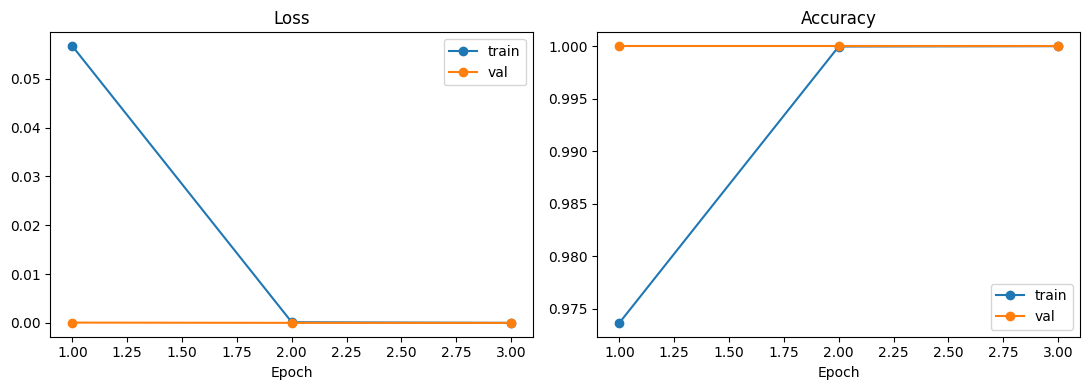

In [ ]:
# STEP 9: Training curves
ep = range(1, len(history) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, [h[0][0] for h in history], marker="o", label="train")
ax[0].plot(ep, [h[1][0] for h in history], marker="o", label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(ep, [h[0][1] for h in history], marker="o", label="train")
ax[1].plot(ep, [h[1][1] for h in history], marker="o", label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Test:   0%|          | 0/62 [00:00<?, ?it/s]

              precision    recall  f1-score   support

        Real     1.0000    0.9995    0.9998      2120
        Fake     0.9994    1.0000    0.9997      1789

    accuracy                         0.9997      3909
   macro avg     0.9997    0.9998    0.9997      3909
weighted avg     0.9997    0.9997    0.9997      3909

Test accuracy: 0.9997
ROC-AUC: 1.0


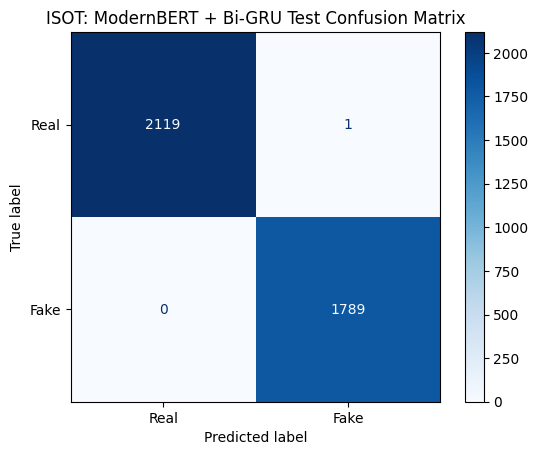

In [ ]:
# STEP 10: Final test evaluation with the best checkpoint
state = torch.load(CKPT, map_location=device)
model.load_state_dict(state, strict=False)
model.eval()

all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Test"):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(batch["input_ids"].to(device), batch["attention_mask"].to(device))
        logits = logits.float()
        all_probs  += torch.softmax(logits, dim=1)[:, 1].cpu().tolist()
        all_preds  += logits.argmax(1).cpu().tolist()
        all_labels += batch["label"].tolist()

print(classification_report(all_labels, all_preds, target_names=["Real", "Fake"], digits=4))
print("Test accuracy:", round(accuracy_score(all_labels, all_preds), 4))
print("ROC-AUC:", round(roc_auc_score(all_labels, all_probs), 4))

cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(cm, display_labels=["Real", "Fake"]).plot(cmap="Blues", values_format="d")
plt.title("ISOT: ModernBERT + Bi-GRU Test Confusion Matrix"); plt.show()

In [ ]:
# STEP 11: Save trainable weights as .h5 (the .pt checkpoint was saved during training)
import h5py
H5_PATH = "modernbert_bigru_isot.h5"

config = {"encoder_name": MODEL_NAME, "hidden_size": HIDDEN_SIZE, "num_layers": NUM_LAYERS,
          "dropout": DROPOUT, "num_classes": 2, "max_len": MAX_LEN,
          "unfreeze_last_n": UNFREEZE_LAST_N, "remove_leakage": REMOVE_LEAKAGE}

with h5py.File(H5_PATH, "w") as f:
    for k, v in config.items():
        f.attrs[k] = v
    g = f.create_group("weights")
    for n, p in model.named_parameters():
        if p.requires_grad:
            g.create_dataset(n, data=p.detach().cpu().numpy(), compression="gzip")
print("Saved", H5_PATH)

# from google.colab import files
# files.download(CKPT); files.download(H5_PATH)

Saved modernbert_bigru_isot.h5


In [ ]:
# STEP 12: Inference helper
@torch.no_grad()
def predict(text):
    model.eval()
    t = clean_text(text) if REMOVE_LEAKAGE else text
    enc = tokenizer(t, max_length=MAX_LEN, truncation=True, return_tensors="pt").to(device)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
        logits = model(enc["input_ids"], enc["attention_mask"])
    probs = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()
    return ("Fake" if probs[1] > probs[0] else "Real"), {"Real": float(probs[0]), "Fake": float(probs[1])}

print(predict("""**Title:** Government Officials Secretly Plan to Cancel National Elections, Anonymous Sources Claim

**Article:**

WASHINGTON — A controversial report circulating on social media claims that several senior government officials have secretly discussed postponing the upcoming national elections without informing the public. The report, which appeared on an unfamiliar political news website earlier this week, alleges that confidential meetings were held behind closed doors to discuss the plan.

According to the article, unnamed individuals supposedly familiar with the discussions said officials were concerned about declining public support and growing political opposition. The report further claims that internal documents were distributed among selected government departments, outlining a proposed schedule for delaying the elections by several months.

The allegations quickly attracted attention online, with several accounts sharing screenshots of the supposed documents. However, the report does not identify the individuals who allegedly attended the meetings, provide verifiable copies of the documents, or cite any official announcement supporting its claims.

Despite the lack of supporting evidence, commentators on social media have presented the allegations as confirmed information. Some posts claim that the decision has already been finalized, while others suggest that an announcement could be made within days.

Government representatives have not been independently verified as having made the statements attributed to them in the circulating report. No authenticated documentation has been provided to establish that the alleged plan exists.

The story continues to circulate across online platforms, illustrating how dramatic political allegations can gain attention before their accuracy has been established. Readers should distinguish between unverified online claims and information supported by reliable evidence.
"""))

('Real', {'Real': 0.6427974104881287, 'Fake': 0.35720252990722656})


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded 23 tensors from /content/best_modernbert_bigru_isot.pt | unexpected: 0 | trainable params NOT in checkpoint: 0 (both should be 0)
Columns: ['Unnamed: 0', 'title', 'text', 'label'] | rows: 6335
After cleaning + dedup: 6298 rows (dropped 37)
label
Real    3153
Fake    3145
Name: count, dtype: int64


McIntire:   0%|          | 0/99 [00:00<?, ?it/s]


===== McIntire cross-dataset (threshold 0.5), n=6298 =====
Acc 0.7504 | P 0.7562 | R 0.7504 | weighted-F1 0.7490 | macro-F1 0.7490 | AUC 0.8272
              precision    recall  f1-score   support

        Real     0.7949    0.6759    0.7305      3153
        Fake     0.7174    0.8251    0.7675      3145

    accuracy                         0.7504      6298
   macro avg     0.7561    0.7505    0.7490      6298
weighted avg     0.7562    0.7504    0.7490      6298

Predicted-Fake rate: 0.574 | true Fake rate: 0.499

[Reference only] best threshold 0.876 -> acc 0.7661 | macro-F1 0.7661  (tuned on test, optimistic)


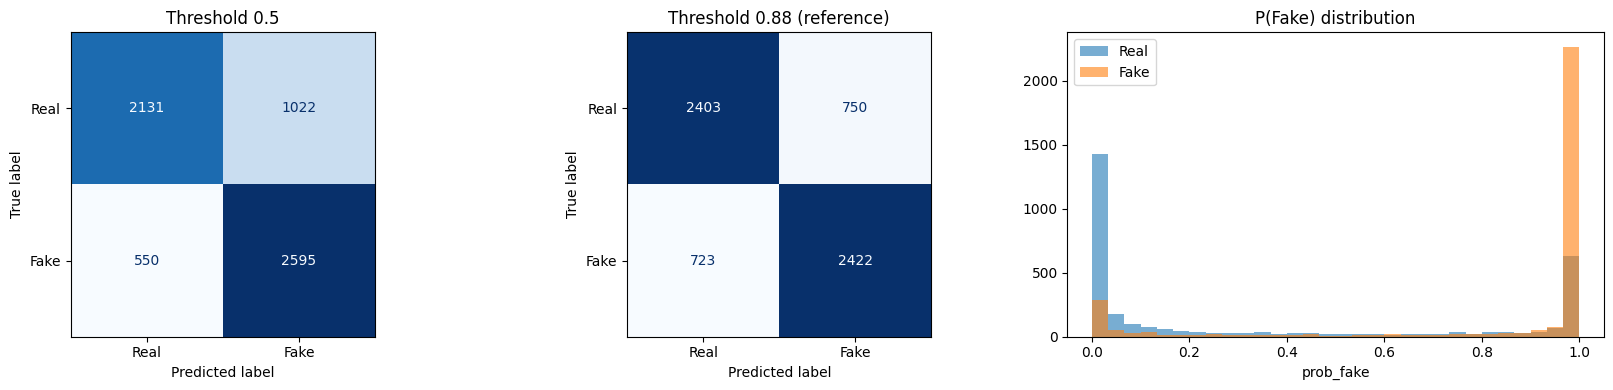


Most confident mistakes:
  true=Real | P(fake)=1.000 | Rush Limbaugh: Left Has 'Fear and Hatred of Christianity'. Pick Your 2016 GOP Candidate -- Let Rush Know! Vote...
  true=Real | P(fake)=1.000 | 7 Times Obama Failed to Support Israel. Should the U.S. Continue to Support Israel?...
  true=Fake | P(fake)=0.000 | 6 neo-Nazis arrested in Motorola assassination case, SBU plot exposed - Fort Russ. 6 neo-Nazis arrested in Mot...
  true=Fake | P(fake)=0.000 | How the internet is making even Ukrainian Nazis into Russians.... November 3, 2016 - Fort Russ - Yurasumy, Pol...
  true=Fake | P(fake)=0.000 | Crimean and Donetsk leaders comment on US elections. November 10, 2016 - Fort Russ News - PolitRussia - transl...


In [ ]:
# STEP 13: Cross-dataset test of the saved ISOT model on McIntire fake_or_real_news.csv
# Preprocessing is IDENTICAL to Step 3 (training): NFKC, lowercase, ASCII-only, leakage removal,
# applied to title and text separately, then joined as "title. text".
import os, re, sys, subprocess, unicodedata, warnings
import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)
warnings.filterwarnings("ignore")

# ftfy repairs mojibake such as "â€™" -> "'" (McIntire has some)
try:
    import ftfy
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ftfy"])
    import ftfy

# ---------------- Config (must match training) ----------------
MODEL_NAME = "answerdotai/ModernBERT-base"
MAX_LEN, BATCH_SIZE = 256, 64
HIDDEN_SIZE, NUM_LAYERS, DROPOUT = 128, 1, 0.3
UNFREEZE_LAST_N = 2

PT_PATH   = "/content/best_modernbert_bigru_isot.pt"
H5_PATH   = "/content/modernbert_bigru_isot.h5"
DATA_PATH = "/content/fake_or_real_news.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()


URL_RE = re.compile(r"https?://\S+|www\.\S+|pic\.twitter\.com/\S+", re.I)
REUTERS_RE = re.compile(r"\(\s*Reuters\s*\)|\bReuters\b", re.I)
CREDIT_RE = re.compile(
    r"^\s*(?:featured\s+)?image\s+via\s+[^\n]{0,120}\.?\s*$|"
    r"^\s*photo\s+by\s+[^\n]{0,120}\.?\s*$|"
    r"^\s*getty\s+images\s*\.?\s*$",
    re.I
)

def clean_text(text: str) -> str:
    t = unicodedata.normalize("NFKC", str(text))

    # Normalize whitespace first so line-anchored credit removal is safe.
    t = "\n".join(line.strip() for line in t.splitlines())

    # Remove URLs.
    t = URL_RE.sub(" ", t)

    # Remove Reuters markers without leaving "( )" behind.
    t = REUTERS_RE.sub(" ", t)

    # Remove only standalone credit/footer lines, not arbitrary text after them.
    t = "\n".join(
        line for line in t.splitlines()
        if not CREDIT_RE.fullmatch(line.strip())
    )

    # Preserve apostrophes and common punctuation; do not destroy contractions.
    t = re.sub(r"[\u2018\u2019]", "'", t)
    t = re.sub(r"[\u201c\u201d]", '"', t)
    t = re.sub(r"\s+", " ", t).strip()

    return t

# ---------------- Model definition (identical to Step 6) ----------------
class ModernBertBiGRU(nn.Module):
    def __init__(self, model_name=MODEL_NAME, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS,
                 dropout=DROPOUT, num_classes=2, unfreeze_last_n=UNFREEZE_LAST_N):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        for p in self.encoder.parameters():
            p.requires_grad = False
        if unfreeze_last_n > 0:
            for layer in self.encoder.layers[-unfreeze_last_n:]:
                for p in layer.parameters():
                    p.requires_grad = True
            for p in self.encoder.final_norm.parameters():
                p.requires_grad = True
        self.gru = nn.GRU(self.encoder.config.hidden_size, hidden_size, num_layers=num_layers,
                          batch_first=True, bidirectional=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * 2 * 2, num_classes)

    def forward(self, input_ids, attention_mask):
        seq = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state.float()
        L = seq.size(1)
        lengths = attention_mask.sum(dim=1).cpu()
        with torch.autocast(device_type="cuda", enabled=False):
            packed = nn.utils.rnn.pack_padded_sequence(seq, lengths, batch_first=True, enforce_sorted=False)
            out, _ = self.gru(packed)
            out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=L)
            m = attention_mask.unsqueeze(-1).float()
            mean_pool = (out * m).sum(1) / m.sum(1).clamp(min=1)
            max_pool = out.masked_fill(m == 0, -1e4).max(1).values
            return self.fc(self.dropout(torch.cat([mean_pool, max_pool], dim=1)))

# ---------------- Load weights (.pt preferred, .h5 fallback) ----------------
test_model = ModernBertBiGRU().to(device)
if os.path.exists(PT_PATH):
    state, src = torch.load(PT_PATH, map_location=device), PT_PATH
elif os.path.exists(H5_PATH):
    with h5py.File(H5_PATH, "r") as f:
        state = {k: torch.tensor(f["weights"][k][()]) for k in f["weights"].keys()}
    src = H5_PATH
else:
    raise FileNotFoundError("Neither the .pt nor the .h5 checkpoint was found")

missing, unexpected = test_model.load_state_dict(state, strict=False)
trainable_names = {n for n, p in test_model.named_parameters() if p.requires_grad}
not_loaded = trainable_names - set(state.keys())
print(f"Loaded {len(state)} tensors from {src} | unexpected: {len(unexpected)} | "
      f"trainable params NOT in checkpoint: {len(not_loaded)} (both should be 0)")
assert len(unexpected) == 0 and len(not_loaded) == 0, "Checkpoint does not match model definition"
test_model.eval()
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# ---------------- Load + prepare McIntire (same pipeline as Step 3) ----------------
try:
    raw = pd.read_csv(DATA_PATH)
except UnicodeDecodeError:
    raw = pd.read_csv(DATA_PATH, encoding="latin-1")
print("Columns:", list(raw.columns), "| rows:", len(raw))

raw["title"] = raw["title"].fillna("").astype(str).apply(ftfy.fix_text)
raw["text"]  = raw["text"].fillna("").astype(str).apply(ftfy.fix_text)
raw.loc[raw["text"].str.strip() == "0", "text"] = ""      # placeholder "0" -> empty

raw["label_str"] = raw["label"].astype(str).str.strip().str.upper()
raw = raw[raw["label_str"].isin(["FAKE", "REAL"])].copy()
raw["label"] = (raw["label_str"] == "FAKE").astype(int)    # FAKE=1, REAL=0 (same as training)

# clean title and text SEPARATELY, then join (exactly like training)
raw["title"] = raw["title"].apply(clean_text)
raw["text"]  = raw["text"].apply(clean_text)
raw["content"] = raw["title"] + ". " + raw["text"]

mc = raw[raw["content"].str.split().str.len() >= 8]
mc = mc.drop_duplicates(subset="content").reset_index(drop=True)
print(f"After cleaning + dedup: {len(mc)} rows (dropped {len(raw) - len(mc)})")
print(mc["label"].value_counts().rename({0: "Real", 1: "Fake"}))

# ---------------- Inference ----------------
class DS(Dataset):
    def __init__(self, texts): self.t = texts
    def __len__(self): return len(self.t)
    def __getitem__(self, i): return self.t[i]

def collate(batch):
    enc = tokenizer(list(batch), max_length=MAX_LEN, padding=True, truncation=True, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]

loader = DataLoader(DS(mc["content"].tolist()), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)
probs = []
with torch.no_grad():
    for ids, mask in tqdm(loader, desc="McIntire"):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = test_model(ids.to(device), mask.to(device))
        probs += torch.softmax(logits.float(), dim=1)[:, 1].cpu().tolist()

mc["prob_fake"] = probs
mc["pred"] = (mc["prob_fake"] > 0.5).astype(int)
y, p = mc["label"].values, mc["pred"].values

# ---------------- Metrics (headline = fixed threshold 0.5) ----------------
pr, rc, f1w, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
print(f"\n===== McIntire cross-dataset (threshold 0.5), n={len(mc)} =====")
print(f"Acc {accuracy_score(y, p):.4f} | P {pr:.4f} | R {rc:.4f} | weighted-F1 {f1w:.4f} "
      f"| macro-F1 {f1_score(y, p, average='macro'):.4f} | AUC {roc_auc_score(y, mc['prob_fake']):.4f}")
print(classification_report(y, p, target_names=["Real", "Fake"], digits=4, zero_division=0))
print(f"Predicted-Fake rate: {p.mean():.3f} | true Fake rate: {y.mean():.3f}")

# Reference only: threshold tuned ON this test set (Youden J), so optimistic. Do not report as the main score.
fpr, tpr, thr = roc_curve(y, mc["prob_fake"])
best_t = thr[np.argmax(tpr - fpr)]
p_t = (mc["prob_fake"] > best_t).astype(int)
print(f"\n[Reference only] best threshold {best_t:.3f} -> acc {accuracy_score(y, p_t):.4f} "
      f"| macro-F1 {f1_score(y, p_t, average='macro'):.4f}  (tuned on test, optimistic)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay(confusion_matrix(y, p, labels=[0, 1]), display_labels=["Real", "Fake"]).plot(
    ax=ax[0], cmap="Blues", values_format="d", colorbar=False); ax[0].set_title("Threshold 0.5")
ConfusionMatrixDisplay(confusion_matrix(y, p_t, labels=[0, 1]), display_labels=["Real", "Fake"]).plot(
    ax=ax[1], cmap="Blues", values_format="d", colorbar=False); ax[1].set_title(f"Threshold {best_t:.2f} (reference)")
ax[2].hist(mc.loc[mc.label == 0, "prob_fake"], bins=30, alpha=0.6, label="Real")
ax[2].hist(mc.loc[mc.label == 1, "prob_fake"], bins=30, alpha=0.6, label="Fake")
ax[2].set_title("P(Fake) distribution"); ax[2].set_xlabel("prob_fake"); ax[2].legend()
plt.tight_layout(); plt.show()

# Most confident mistakes
wrong = mc[mc["pred"] != mc["label"]].copy()
wrong["conf"] = (wrong["prob_fake"] - 0.5).abs()
print("\nMost confident mistakes:")
for _, r in wrong.sort_values("conf", ascending=False).head(5).iterrows():
    print(f"  true={'Fake' if r.label else 'Real'} | P(fake)={r.prob_fake:.3f} | {r.content[:110]}...")

In [1]:
# STEP 14: 5-fold stratified cross-validation on ISOT
import os, re, gc, json, time, random, sys, subprocess, unicodedata, warnings
import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, roc_auc_score)
warnings.filterwarnings("ignore")

# ---------------- Config (identical to training) ----------------
MODEL_NAME = "answerdotai/ModernBERT-base"
MAX_LEN, TRAIN_BS, EVAL_BS = 256, 32, 64
SEED = 42
HIDDEN_SIZE, NUM_LAYERS, DROPOUT = 128, 1, 0.3
UNFREEZE_LAST_N = 2
LR_HEAD, LR_ENCODER = 1e-3, 2e-5

N_SPLITS  = 5
CV_EPOCHS = 2            # epochs per fold (fixed, no early stopping on the held-out fold)
CV_MODE   = "retrain"    # "retrain" = proper CV | "saved_model" = no training, but leaky (see note)

ISOT_TRUE, ISOT_FAKE = "/content/True.csv", "/content/Fake.csv"
PT_PATH, H5_PATH = "/content/best_modernbert_bigru_isot.pt", "/content/modernbert_bigru_isot.h5"
CV_RESULTS_PATH = f"/content/cv_isot_{CV_MODE}.json"

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# ---------------- Cleaning (identical to Step 3) ----------------
URL_RE = re.compile(r"https?://\S+|www\.\S+|pic\.twitter\.com/\S+", re.I)
REUTERS_RE = re.compile(r"\(\s*Reuters\s*\)|\bReuters\b", re.I)
CREDIT_RE = re.compile(
    r"^\s*(?:featured\s+)?image\s+via\s+[^\n]{0,120}\.?\s*$|"
    r"^\s*photo\s+by\s+[^\n]{0,120}\.?\s*$|"
    r"^\s*getty\s+images\s*\.?\s*$", re.I)

def clean_text(text: str) -> str:
    t = unicodedata.normalize("NFKC", str(text))
    t = "\n".join(line.strip() for line in t.splitlines())
    t = URL_RE.sub(" ", t)
    t = REUTERS_RE.sub(" ", t)
    t = "\n".join(line for line in t.splitlines() if not CREDIT_RE.fullmatch(line.strip()))
    t = re.sub(r"[\u2018\u2019]", "'", t)
    t = re.sub(r"[\u201c\u201d]", '"', t)
    return re.sub(r"\s+", " ", t).strip()

def load_isot():
    t, f = pd.read_csv(ISOT_TRUE), pd.read_csv(ISOT_FAKE)
    t["label"], f["label"] = 0, 1                      # Real=0, Fake=1
    d = pd.concat([t, f], ignore_index=True)
    d["title"] = d["title"].fillna("").apply(clean_text)
    d["text"]  = d["text"].fillna("").apply(clean_text)
    d["content"] = d["title"] + ". " + d["text"]
    d = d[d["content"].str.split().str.len() >= 8]
    d = d.drop_duplicates("content").reset_index(drop=True)
    d = d.sample(frac=1, random_state=SEED).reset_index(drop=True)
    return d[["content", "label"]]

isot_df = load_isot()
print("ISOT:", isot_df.shape, dict(isot_df["label"].value_counts().rename({0: "Real", 1: "Fake"})))

# Same 80/10/10 split as Step 4 (used later for the held-out ISOT test in Steps 16-17)
isot_train, _tmp = train_test_split(isot_df, test_size=0.20, stratify=isot_df["label"], random_state=SEED)
isot_val, isot_test = train_test_split(_tmp, test_size=0.50, stratify=_tmp["label"], random_state=SEED)

# 5 stratified folds over the full deduplicated ISOT (reused by Step 15 for the baselines)
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(skf.split(isot_df["content"], isot_df["label"]))

# ---------------- Model (identical to Step 6) ----------------
class ModernBertBiGRU(nn.Module):
    def __init__(self, model_name=MODEL_NAME, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS,
                 dropout=DROPOUT, num_classes=2, unfreeze_last_n=UNFREEZE_LAST_N):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        for p in self.encoder.parameters():
            p.requires_grad = False
        if unfreeze_last_n > 0:
            for layer in self.encoder.layers[-unfreeze_last_n:]:
                for p in layer.parameters():
                    p.requires_grad = True
            for p in self.encoder.final_norm.parameters():
                p.requires_grad = True
        self.gru = nn.GRU(self.encoder.config.hidden_size, hidden_size, num_layers=num_layers,
                          batch_first=True, bidirectional=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * 2 * 2, num_classes)

    def forward(self, input_ids, attention_mask):
        seq = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state.float()
        L = seq.size(1)
        lengths = attention_mask.sum(dim=1).cpu()
        with torch.autocast(device_type="cuda", enabled=False):
            packed = nn.utils.rnn.pack_padded_sequence(seq, lengths, batch_first=True, enforce_sorted=False)
            out, _ = self.gru(packed)
            out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=L)
            m = attention_mask.unsqueeze(-1).float()
            mean_pool = (out * m).sum(1) / m.sum(1).clamp(min=1)
            max_pool = out.masked_fill(m == 0, -1e4).max(1).values
            return self.fc(self.dropout(torch.cat([mean_pool, max_pool], dim=1)))

def load_saved_model():
    """Loads your trained ISOT model from .pt (preferred) or .h5."""
    m = ModernBertBiGRU().to(device)
    if os.path.exists(PT_PATH):
        state = torch.load(PT_PATH, map_location=device)
    elif os.path.exists(H5_PATH):
        with h5py.File(H5_PATH, "r") as f:
            state = {k: torch.tensor(f["weights"][k][()]) for k in f["weights"].keys()}
    else:
        raise FileNotFoundError("Neither the .pt nor the .h5 checkpoint was found")
    _, unexpected = m.load_state_dict(state, strict=False)
    trainable = {n for n, p in m.named_parameters() if p.requires_grad}
    assert len(unexpected) == 0 and len(trainable - set(state.keys())) == 0, "Checkpoint mismatch"
    return m.eval()

# ---------------- Data / eval helpers (reused in Step 16) ----------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class TextDS(Dataset):
    def __init__(self, texts, labels): self.t, self.y = list(texts), list(labels)
    def __len__(self): return len(self.t)
    def __getitem__(self, i): return self.t[i], self.y[i]

def collate_fn(batch):
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), max_length=MAX_LEN, padding=True, truncation=True, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"], torch.tensor(labels, dtype=torch.long)

def make_loader(texts, labels, bs, shuffle=False):
    g = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(TextDS(texts, labels), batch_size=bs, shuffle=shuffle,
                      collate_fn=collate_fn, generator=g)

@torch.no_grad()
def predict_probs(model, loader, desc="Eval"):
    model.eval(); probs, ys = [], []
    for ids, mask, y in tqdm(loader, desc=desc, leave=False):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(ids.to(device), mask.to(device))
        probs += torch.softmax(logits.float(), dim=1)[:, 1].cpu().tolist()
        ys += y.tolist()
    return np.array(probs), np.array(ys)

def compute_metrics(y, prob, thr=0.5):
    p = (prob > thr).astype(int)
    pr, rc, f1w, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    return {"accuracy": float(accuracy_score(y, p)), "precision": float(pr), "recall": float(rc),
            "f1": float(f1w), "macro_f1": float(f1_score(y, p, average="macro")),
            "auc": float(roc_auc_score(y, prob))}

# ---------------- Train one fold (same recipe as Steps 7-8) ----------------
def train_one_fold(tr_idx, va_idx, fold):
    set_seed(SEED + fold)
    tr, va = isot_df.iloc[tr_idx], isot_df.iloc[va_idx]
    tr_loader = make_loader(tr["content"], tr["label"], TRAIN_BS, shuffle=True)
    va_loader = make_loader(va["content"], va["label"], EVAL_BS)

    model = ModernBertBiGRU().to(device)
    enc_params  = [p for p in model.encoder.parameters() if p.requires_grad]
    head_params = list(model.gru.parameters()) + list(model.fc.parameters())
    optimizer = torch.optim.AdamW([{"params": head_params, "lr": LR_HEAD},
                                   {"params": enc_params,  "lr": LR_ENCODER}], weight_decay=0.01)
    total_steps = len(tr_loader) * CV_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=tr["label"].values)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float).to(device))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    for epoch in range(1, CV_EPOCHS + 1):
        model.train()
        pbar = tqdm(tr_loader, desc=f"Fold {fold+1}/{N_SPLITS} | epoch {epoch}/{CV_EPOCHS}")
        for ids, mask, y in pbar:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(ids, mask)
            loss = criterion(logits.float(), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(head_params + enc_params, 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            pbar.set_postfix(loss=f"{loss.item():.4f}")

    prob, y = predict_probs(model, va_loader, f"Fold {fold+1} eval")
    m = compute_metrics(y, prob)
    del model, optimizer, scheduler, scaler
    gc.collect(); torch.cuda.empty_cache()
    return m

# ---------------- Run CV (resumable) ----------------
results = json.load(open(CV_RESULTS_PATH)) if os.path.exists(CV_RESULTS_PATH) else {}
saved_model = load_saved_model() if CV_MODE == "saved_model" else None

for k, (tr_idx, va_idx) in enumerate(folds):
    if str(k) in results:
        print(f"Fold {k+1}: already done, skipping"); continue
    t0 = time.time()
    if CV_MODE == "retrain":
        m = train_one_fold(tr_idx, va_idx, k)
    else:
        va = isot_df.iloc[va_idx]
        prob, y = predict_probs(saved_model, make_loader(va["content"], va["label"], EVAL_BS), f"Fold {k+1}")
        m = compute_metrics(y, prob)
    results[str(k)] = m
    json.dump(results, open(CV_RESULTS_PATH, "w"))
    print(f"Fold {k+1}: acc {m['accuracy']:.4f} | F1 {m['f1']:.4f} | AUC {m['auc']:.4f} "
          f"({(time.time()-t0)/60:.1f} min)")

cv_results = [results[str(k)] for k in range(N_SPLITS)]
cv_df = pd.DataFrame(cv_results); cv_df.index = [f"Fold {i+1}" for i in range(N_SPLITS)]
summary = pd.DataFrame({"mean": cv_df.mean(), "std": cv_df.std()}).T
print(f"\n===== 5-fold stratified CV on ISOT (mode: {CV_MODE}) =====")
print(pd.concat([cv_df, summary]).round(4).to_string())
if CV_MODE == "saved_model":
    print("\nWARNING: the saved model was trained on ~80% of every fold, so these scores are "
          "optimistic. Use CV_MODE='retrain' for the paper.")

ISOT: (39085, 2) {'Real': np.int64(21194), 'Fake': np.int64(17891)}


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

...

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fold 5/5 | epoch 1/2:   0%|          | 0/978 [00:00<?, ?it/s]

Fold 5/5 | epoch 2/2:   0%|          | 0/978 [00:00<?, ?it/s]

Fold 5 eval:   0%|          | 0/123 [00:00<?, ?it/s]

Fold 5: acc 1.0000 | F1 1.0000 | AUC 1.0000 (12.7 min)

===== 5-fold stratified CV on ISOT (mode: retrain) =====
        accuracy  precision  recall      f1  macro_f1  auc
Fold 1    1.0000     1.0000  1.0000  1.0000    1.0000  1.0
Fold 2    1.0000     1.0000  1.0000  1.0000    1.0000  1.0
Fold 3    0.9999     0.9999  0.9999  0.9999    0.9999  1.0
Fold 4    1.0000     1.0000  1.0000  1.0000    1.0000  1.0
Fold 5    1.0000     1.0000  1.0000  1.0000    1.0000  1.0
mean      1.0000     1.0000  1.0000  1.0000    1.0000  1.0
std       0.0001     0.0001  0.0001  0.0001    0.0001  0.0


In [9]:
# STEP 14b: 5-fold stratified cross-validation on the McIntire dataset
import sys, subprocess
assert "ModernBertBiGRU" in globals() and "compute_metrics" in globals(), "Run Step 14 first"
try:
    import ftfy
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ftfy"]); import ftfy

EXT_PATH       = "/content/fake_or_real_news.csv"
EXT_CV_EPOCHS  = 3        # McIntire is small (~6k articles), so 3 epochs per fold is cheap
INIT_FROM_ISOT = False    # False = train from scratch | True = start from the saved ISOT weights
EXT_RESULTS_PATH = f"/content/cv_mcintire_{'isotinit' if INIT_FROM_ISOT else 'scratch'}.json"

# ---------------- Load McIntire (same pipeline as Steps 3 / 13 / 16) ----------------
if "ext_df" not in globals():
    try:
        raw = pd.read_csv(EXT_PATH)
    except UnicodeDecodeError:
        raw = pd.read_csv(EXT_PATH, encoding="latin-1")
    raw["title"] = raw["title"].fillna("").astype(str).apply(ftfy.fix_text)
    raw["text"]  = raw["text"].fillna("").astype(str).apply(ftfy.fix_text)
    raw.loc[raw["text"].str.strip() == "0", "text"] = ""
    raw["label_str"] = raw["label"].astype(str).str.strip().str.upper()
    raw = raw[raw["label_str"].isin(["FAKE", "REAL"])].copy()
    raw["label"] = (raw["label_str"] == "FAKE").astype(int)      # FAKE=1, REAL=0
    raw["title"] = raw["title"].apply(clean_text)
    raw["text"]  = raw["text"].apply(clean_text)
    raw["content"] = raw["title"] + ". " + raw["text"]
    ext_df = raw[raw["content"].str.split().str.len() >= 8].drop_duplicates("content").reset_index(drop=True)
    ext_df = ext_df[["content", "label"]]
ext_df = ext_df.sample(frac=1, random_state=SEED).reset_index(drop=True)
print("McIntire:", ext_df.shape, dict(ext_df["label"].value_counts().rename({0: "Real", 1: "Fake"})))

ext_skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
ext_folds = list(ext_skf.split(ext_df["content"], ext_df["label"]))

# ---------------- Optional: ISOT weights as initialisation ----------------
def load_isot_state():
    if os.path.exists(PT_PATH):
        return torch.load(PT_PATH, map_location=device)
    with h5py.File(H5_PATH, "r") as f:
        return {k: torch.tensor(f["weights"][k][()]) for k in f["weights"].keys()}
isot_state = load_isot_state() if INIT_FROM_ISOT else None

# ---------------- Train one fold (same recipe as Step 14) ----------------
def train_one_fold_ext(tr_idx, va_idx, fold):
    set_seed(SEED + fold)
    tr, va = ext_df.iloc[tr_idx], ext_df.iloc[va_idx]
    tr_loader = make_loader(tr["content"], tr["label"], TRAIN_BS, shuffle=True)
    va_loader = make_loader(va["content"], va["label"], EVAL_BS)

    model = ModernBertBiGRU().to(device)
    if isot_state is not None:
        model.load_state_dict(isot_state, strict=False)
    enc_params  = [p for p in model.encoder.parameters() if p.requires_grad]
    head_params = list(model.gru.parameters()) + list(model.fc.parameters())
    optimizer = torch.optim.AdamW([{"params": head_params, "lr": LR_HEAD},
                                   {"params": enc_params,  "lr": LR_ENCODER}], weight_decay=0.01)
    total_steps = len(tr_loader) * EXT_CV_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=tr["label"].values)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float).to(device))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    for epoch in range(1, EXT_CV_EPOCHS + 1):
        model.train()
        pbar = tqdm(tr_loader, desc=f"McIntire fold {fold+1}/{N_SPLITS} | epoch {epoch}/{EXT_CV_EPOCHS}")
        for ids, mask, y in pbar:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(ids, mask)
            loss = criterion(logits.float(), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(head_params + enc_params, 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            pbar.set_postfix(loss=f"{loss.item():.4f}")

    prob, y = predict_probs(model, va_loader, f"McIntire fold {fold+1} eval")
    m = compute_metrics(y, prob)
    del model, optimizer, scheduler, scaler
    gc.collect(); torch.cuda.empty_cache()
    return m

# ---------------- Run CV (resumable) ----------------
ext_results = json.load(open(EXT_RESULTS_PATH)) if os.path.exists(EXT_RESULTS_PATH) else {}
for k, (tr_idx, va_idx) in enumerate(ext_folds):
    if str(k) in ext_results:
        print(f"Fold {k+1}: already done, skipping"); continue
    t0 = time.time()
    m = train_one_fold_ext(tr_idx, va_idx, k)
    ext_results[str(k)] = m
    json.dump(ext_results, open(EXT_RESULTS_PATH, "w"))
    print(f"Fold {k+1}: acc {m['accuracy']:.4f} | F1 {m['f1']:.4f} | AUC {m['auc']:.4f} "
          f"({(time.time()-t0)/60:.1f} min)")

ext_cv_results = [ext_results[str(k)] for k in range(N_SPLITS)]
ext_cv_df = pd.DataFrame(ext_cv_results); ext_cv_df.index = [f"Fold {i+1}" for i in range(N_SPLITS)]
ext_summary = pd.DataFrame({"mean": ext_cv_df.mean(), "std": ext_cv_df.std()}).T
init_txt = "initialised from ISOT weights" if INIT_FROM_ISOT else "trained from scratch"
print(f"\n===== 5-fold stratified CV on McIntire ({init_txt}) =====")
print(pd.concat([ext_cv_df, ext_summary]).round(4).to_string())

McIntire: (6298, 2) {'Real': np.int64(3153), 'Fake': np.int64(3145)}
Fold 1: already done, skipping
Fold 2: already done, skipping
Fold 3: already done, skipping
Fold 4: already done, skipping
Fold 5: already done, skipping

===== 5-fold stratified CV on McIntire (trained from scratch) =====
        accuracy  precision  recall      f1  macro_f1     auc
Fold 1    0.9706     0.9708  0.9706  0.9706    0.9706  0.9971
Fold 2    0.9714     0.9714  0.9714  0.9714    0.9714  0.9956
Fold 3    0.9706     0.9706  0.9706  0.9706    0.9706  0.9953
Fold 4    0.9762     0.9762  0.9762  0.9762    0.9762  0.9973
Fold 5    0.9674     0.9677  0.9674  0.9674    0.9674  0.9947
mean      0.9713     0.9714  0.9713  0.9713    0.9713  0.9960
std       0.0031     0.0031  0.0031  0.0031    0.0031  0.0011


Table 3: 5-fold stratified CV, ISOT vs McIntire
              ISOT (mean ± std) McIntire (mean ± std)  Difference (ISOT - McIntire)
Metric                                                                             
Accuracy        1.0000 ± 0.0001       0.9713 ± 0.0031                        0.0287
Precision       1.0000 ± 0.0001       0.9714 ± 0.0031                        0.0286
Recall          1.0000 ± 0.0001       0.9713 ± 0.0031                        0.0287
F1 (weighted)   1.0000 ± 0.0001       0.9713 ± 0.0031                        0.0287
Macro-F1        1.0000 ± 0.0001       0.9713 ± 0.0031                        0.0287
AUC             1.0000 ± 0.0000       0.9960 ± 0.0011                        0.0040

Per-fold results
       Accuracy          Precision           Recall          F1 (weighted)          Macro-F1           AUC         
           ISOT McIntire      ISOT McIntire    ISOT McIntire          ISOT McIntire     ISOT McIntire ISOT McIntire
Fold 1   1.0000   0.9706    1.

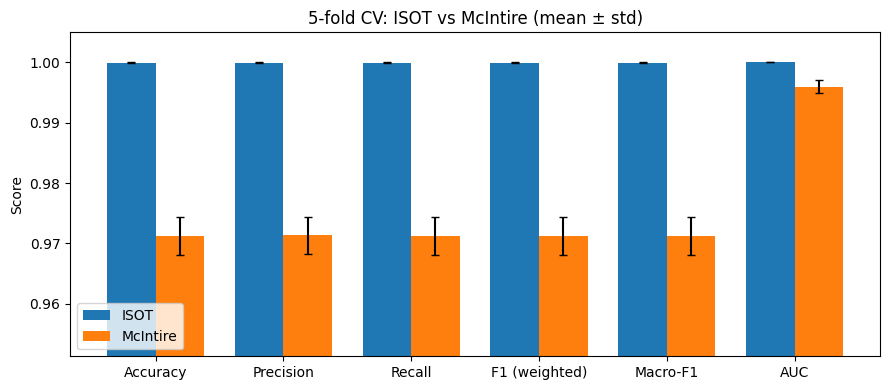

In [10]:
# STEP 17: Comparison table - 5-fold stratified CV on ISOT vs McIntire
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

assert "cv_df" in globals() and "ext_cv_df" in globals(), "Run Step 14 and Step 14b first"

metrics = ["accuracy", "precision", "recall", "f1", "macro_f1", "auc"]
labels  = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
           "f1": "F1 (weighted)", "macro_f1": "Macro-F1", "auc": "AUC"}

# ---- Table 1: summary (mean +/- std over the 5 folds) ----
rows = []
for m in metrics:
    i_mean, i_std = cv_df[m].mean(),     cv_df[m].std()
    e_mean, e_std = ext_cv_df[m].mean(), ext_cv_df[m].std()
    rows.append({
        "Metric": labels[m],
        "ISOT (mean ± std)":     f"{i_mean:.4f} ± {i_std:.4f}",
        "McIntire (mean ± std)": f"{e_mean:.4f} ± {e_std:.4f}",
        "Difference (ISOT - McIntire)": round(i_mean - e_mean, 4),
    })
summary_cmp = pd.DataFrame(rows).set_index("Metric")
print("Table 3: 5-fold stratified CV, ISOT vs McIntire")
print(summary_cmp.to_string())

# ---- Table 2: fold-by-fold comparison ----
per_fold = pd.concat({"ISOT": cv_df[metrics], "McIntire": ext_cv_df[metrics]}, axis=1)
per_fold = per_fold.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
per_fold = per_fold[[(m, d) for m in metrics for d in ("ISOT", "McIntire")]]
per_fold.columns = pd.MultiIndex.from_tuples([(labels[m], d) for m, d in per_fold.columns])
print("\nPer-fold results")
print(per_fold.round(4).to_string())

# ---- Dataset info ----
if "isot_df" in globals() and "ext_df" in globals():
    print(f"\nISOT: {len(isot_df)} articles | McIntire: {len(ext_df)} articles")

# ---- Chart: mean +/- std per metric ----
x = np.arange(len(metrics)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2, [cv_df[m].mean() for m in metrics],     w,
       yerr=[cv_df[m].std() for m in metrics],     capsize=3, label="ISOT")
ax.bar(x + w/2, [ext_cv_df[m].mean() for m in metrics], w,
       yerr=[ext_cv_df[m].std() for m in metrics], capsize=3, label="McIntire")
lo = min(min(cv_df[m].mean() for m in metrics), min(ext_cv_df[m].mean() for m in metrics))
ax.set_ylim(max(0, lo - 0.02), 1.005)
ax.set_xticks(x); ax.set_xticklabels([labels[m] for m in metrics])
ax.set_ylabel("Score"); ax.set_title("5-fold CV: ISOT vs McIntire (mean ± std)")
ax.legend(); plt.tight_layout(); plt.show()

# ---- Save for the paper ----
summary_cmp.to_csv("cv_comparison_isot_vs_mcintire.csv")